In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    print("💻 ローカル / ホスト環境で実行中。ルート:", repo_root)


💻 ローカル / ホスト環境で実行中。ルート: /home/student/Documents/GitHub/study-mikanos


# 7.5 MSI割り込み (`Configuring PCI MSI Interrupts`)

本節では、名著『ゼロからのOS自作入門』（内田公太 著、マイナビ出版）の第7章「割り込みとFIFO」7.5節に基づき、PCIデバイス（特にUSB 3.0ホストコントローラ **xHCI**）からCPUへ割り込みを通知する中核機構である **MSI (Message Signaled Interrupts)** の原理、PCIコンフィギュレーション空間におけるケーパビリティ単方向連結リストの走査アルゴリズム、および Local APIC 向けメッセージアドレス・データの数理ビット導出を徹底解説します。

> [!IMPORTANT]
> **本節の学習目標 (Learning Objectives)**:
> 1. **レガシー割り込み (INTxピン) の限界と MSI の圧倒的優位性**: 物理配線の共有（Wire-OR）によるポーリングペナルティを解消し、PCIeのメモリ書き込みトランザクションとして割り込みを送る MSI/MSI-X の動作原理を理解する。
> 2. **PCI ケーパビリティ単方向連結リストの走査**: オフセット `0x34` の `Capabilities Pointer` から始まる単方向リストを辿り、MSI ケーパビリティ（ID: `0x05`）を特定するアルゴリズムを習得する。
> 3. **Local APIC メッセージアドレス・データの完全ビット導出**: 宛先 Local APIC アドレス `0xFEE00000 | (apic_id << 12)`、およびベクタ番号 `0x40` とレベルトリガー設定 `0xC000` の数理構造を理解する。
> 4. **MikanOS カーネル初期化フローとの結合**: `IDT` 登録 → `MSI` 設定 → `xHCI.Run()` → `sti`（割り込み許可）によるイベント駆動型 OS への昇華シーケンスを体得する。


## 1. 従来のピン割り込み (Legacy INTx) vs メッセージシグナル割り込み (MSI)

### 1.1 前節までの実装が抱えていた「ミッシングリンク」
前節（7.4節）では、x86-64 CPU内部の **IDT (Interrupt Descriptor Table)** にベクタ番号 `0x40`（64番）の割り込みゲート記述子を設定し、`LIDT` 命令で CPU に登録しました。また、ベクタ `0x40` のハンドラとして `IntHandlerXHCI`（`__attribute__((interrupt))`）を用意しました。

しかし、**「マウスを動かしたとき、xHCI ハードウェアはどうやって CPU にベクタ 0x40 の割り込みを発生させるのか？」** という肝心の接続部分が未設定のままでした。このハードウェアと CPU の橋渡しを行うのが **MSI (Message Signaled Interrupts)** です。

---

### 1.2 従来のピン割り込み (Legacy Pin-based Interrupts: INTA#〜INTD#)
1990年代に制定された従来の PCI 仕様では、デバイスはマザーボード上の物理的な割り込みピン（`INTA#`, `INTB#`, `INTC#`, `INTD#`）をグラウンド（Low）に引き下げることで割り込みを要求していました。

```
[デバイス A] ──┐
               ├─────(共有配線 INTA#)─────> [I/O APIC / 8259 PIC] ───> [CPU]
[デバイス B] ──┘
```

このレガシー方式には、現代のマルチコア PC において致命的な **4大ボトルネック** が存在しました：

1. **物理ピン数の不足（最大4本）**: マザーボード上に引ける物理配線には限りがあり、PCI スロットが増えるとピン数が不足します。
2. **割り込みピンの共有 (Interrupt Sharing)**: ピンが足りないため、複数のデバイス（例: サウンドカードとUSBコントローラ）が同一の `INTA#` ピンに配線されます（Wire-OR 回路）。
3. **OS のポーリングオーバーヘッド**: `INTA#` 割り込みが発生した際、CPU は「どのデバイスが割り込みを要求したのか」を判別できません。そのため、OS は共有されている全デバイスのステータスレジスタを順に読み出して（低速な PCI バストランザクションを発生させて）発生源を特定しなければなりませんでした。
4. **マルチコア親和性の欠如**: 物理配線が特定の I/O APIC ピンに固定されているため、特定コア（Core 0）に割り込みが集中し、他コアへの柔軟な負荷分散が困難でした。

---

### 1.3 MSI (Message Signaled Interrupts) の革新的アーキテクチャ
2004年に策定された PCI 2.2 / PCI Express (PCIe) で導入されたのが **MSI (Message Signaled Interrupts)** です。

MSI では、**物理的な割り込みピン配線が完全に不要** です。その代わり、デバイス自身がバスマスタとなって、**特定のアドレス（Local APIC のメッセージアドレス）に対して、特定のデータ（ベクタ番号を含むメッセージ）を通常のメモリ書き込みトランザクション（Memory Write Request Packet）として送信** します。

```mermaid
sequenceDiagram
    autonumber
    participant Mouse as USB マウス
    participant xHCI as xHCI コントローラ (PCIe)
    participant PCIe as PCIe スイッチ / ファブリック
    participant LAPIC as Local APIC (CPU 0)
    participant CPU as CPU コア (IDT)

    Mouse->>xHCI: マウス移動パケット受信
    Note over xHCI: Event Ring に TRB を追記
    xHCI->>PCIe: PCIe Memory Write Packet 発行<br/>宛先アドレス: 0xFEE00000<br/>書込データ: 0xC040
    PCIe->>LAPIC: Local APIC レジスタへ直接到達
    Note over LAPIC: ベクタ 0x40 の割り込み要求をラッチ (IRR)
    LAPIC->>CPU: CPU コアへ割り込み通知 (ベクタ 0x40)
    CPU->>CPU: IDT[0x40] を参照して IntHandlerXHCI 起動!
```

#### 🚀 MSI の圧倒的な技術的優位性:
- **ピン完全不要**: 通常のデータ転送と同じ PCIe パケットとして処理されるため、配線設計がシンプル化。
- **共有の完全排除 (No Sharing)**: デバイスごと、さらにはイベント（送信完了、受信完了、エラーなど）ごとに独立した割り込みベクタ番号を直接指定可能。
- **ポーリングゼロ**: CPU は割り込みを受信した時点で発生元デバイスとイベント種別を一意に特定できるため、無駄なレジスタ走査が一切不要。
- **マルチコア完全最適化**: 送信先アドレスにターゲット CPU コアの **Local APIC ID** を含めることができるため、マルチコア環境で任意のコアへ割り込みを直接ルーティング可能。


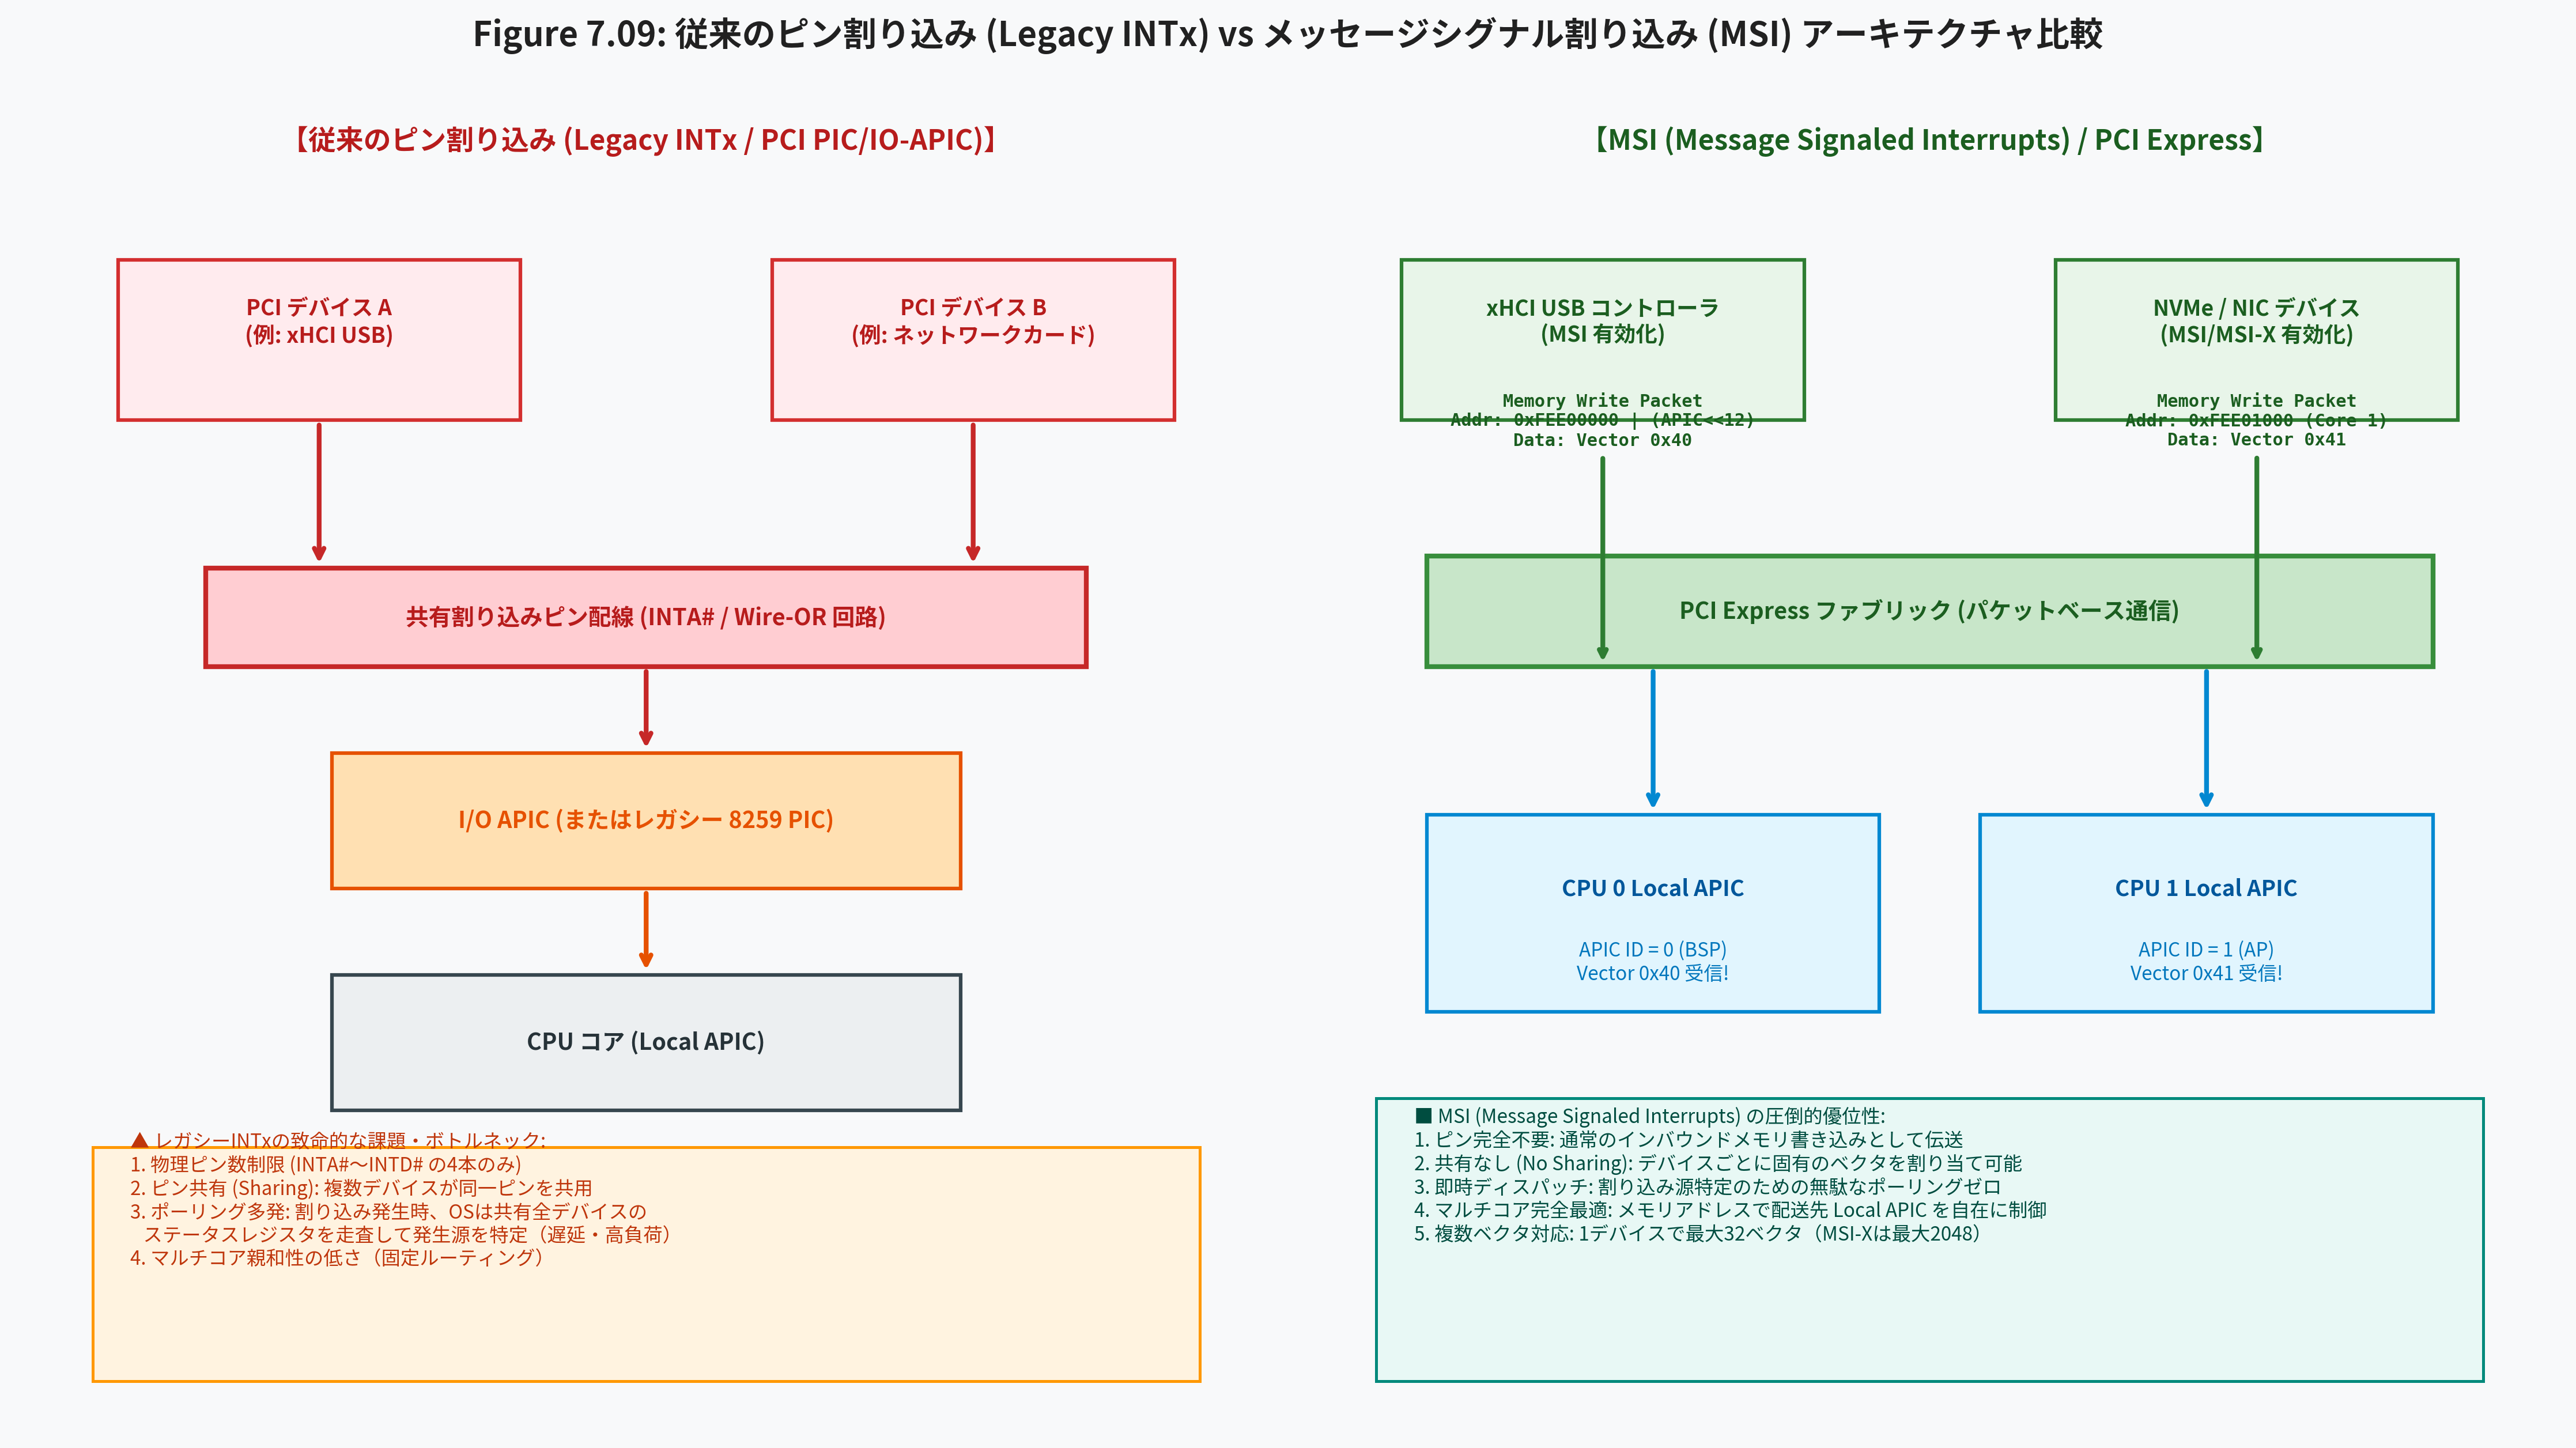

In [2]:
# Figure 7.09: レガシー割り込み (INTx) vs メッセージシグナル割り込み (MSI) アーキテクチャ比較
import common
from IPython.display import Image, display

fig7_09_path = "result/fig7_09_msi_vs_legacy_interrupts.png"
common.plot_msi_vs_legacy_interrupts(fig7_09_path)
display(Image(filename=fig7_09_path, width=950))


## 2. PCI コンフィギュレーション空間とケーパビリティ単方向連結リスト

### 2.1 PCI ケーパビリティ構造の動機
第6章 6.3節で学んだように、PCI デバイスには 256 バイトの **コンフィギュレーション空間 (Configuration Space)** が割り当てられています。その先頭 64 バイト（`0x00`〜`0x3F`）は全デバイス共通の基本ヘッダ（Vendor ID, Device ID, Status, Command, Class Code, BAR0〜5 など）で固定されています。

しかし、電源管理（PCI Power Management）、ホットプラグ、PCI Express 固有機能、そして **MSI / MSI-X** などの拡張機能はデバイスによってサポート状況が異なります。これら可変個の拡張機能を限られた空間に柔軟に配置するため、PCI 規格では **単方向連結リスト (Singly Linked List)** による「ケーパビリティ構造」が採用されました。

---

### 2.2 ケーパビリティリストの走査アルゴリズム
PCI Configuration Header Type 00h において、オフセット `0x34` に 8 ビットの **Capabilities Pointer (`CapPtr`)** が配置されています（※Status レジスタの bit 4 `Capabilities List` が 1 のとき有効）。

各ケーパビリティノードの構造は以下の 32 ビット共通ヘッダで始まります：

```text
PCI Capability Header (32 bits = 4 Bytes):
+-------------------------------+-------------------------------+-------------------------------+
|      Bits 31 .. 16 (16 bits)   |      Bits 15 .. 8 (8 bits)    |      Bits 7 .. 0 (8 bits)     |
|   Capability Specific (cap)   |   Next Pointer (next_ptr)     |   Capability ID (cap_id)      |
+-------------------------------+-------------------------------+-------------------------------+
```

- **`cap_id` (8 bits)**: ケーパビリティの種類を示す識別子。
  - `0x01`: PCI Power Management (PM)
  - `0x05`: **MSI (Message Signaled Interrupts)** ✨ 本節のターゲット！
  - `0x10`: PCI Express Capability
  - `0x11`: **MSI-X** (拡張MSI: 最大2048ベクタ対応)
- **`next_ptr` (8 bits)**: 次のケーパビリティノードのコンフィギュレーション空間内バイトオフセット（`0x40`〜`0xFC`）。**`0x00` であればリスト終端 (End of List)** を表します。

```text
【ケーパビリティ単方向連結リストの探索フロー】
Offset 0x34 [CapPtr = 0x50] 
       │
       ▼
Offset 0x50 [CapID = 0x01 (PM), Next = 0x80] ──(不一致: 次へ)──┐
                                                               │
       ┌───────────────────────────────────────────────────────┘
       ▼
Offset 0x80 [CapID = 0x05 (MSI), Next = 0x00] ──(一致: ターゲット発見!)
```

MikanOS（`kernel/pci.cpp`）では、以下のようにループでリストを辿り、MSI ケーパビリティのアドレス（`msi_cap_addr`）を特定します：

```cpp
// kernel/pci.cpp: ConfigureMSI 実装
uint8_t cap_addr = ReadConfReg(dev, 0x34) & 0xffu;
uint8_t msi_cap_addr = 0, msix_cap_addr = 0;
while (cap_addr != 0) {
  auto header = ReadCapabilityHeader(dev, cap_addr);
  if (header.bits.cap_id == kCapabilityMSI) {
    msi_cap_addr = cap_addr;
  } else if (header.bits.cap_id == kCapabilityMSIX) {
    msix_cap_addr = cap_addr;
  }
  cap_addr = header.bits.next_ptr; // 次のノードのオフセットへ進む
}
```


## 3. MSI ケーパビリティ構造のレジスタレイアウト

### 3.1 32ビットアドレス版 vs 64ビットアドレス版の差異
MSI ケーパビリティは、デバイスが 64 ビットアドレスへのメッセージ書き込みをサポートしているか否か（`addr_64_capable`）によって構造体のサイズとオフセットが動的に変化します。

```text
【32-bit Address Capable の場合 (12 Bytes)】
  +0x00: [Message Control (16b)] [Next Ptr (8b)] [Cap ID = 0x05 (8b)]
  +0x04: [Message Address (32b)]
  +0x08: [Message Data (16b) / Reserved (16b)]

【64-bit Address Capable の場合 (16 Bytes)】★現代のPC/xHCIはこちら
  +0x00: [Message Control (16b)] [Next Ptr (8b)] [Cap ID = 0x05 (8b)]
  +0x04: [Message Address (32b)]
  +0x08: [Message Upper Address (32b)]   <--- 上位32ビットアドレスが挿入される!
  +0x0C: [Message Data (16b) / Reserved (16b)]
```

> [!WARNING]
> **レジスタオフセットの落とし穴**:
> 64ビット対応フラグ（`addr_64_capable`）が 1 の場合、`Message Upper Address` レジスタが間に挟まるため、**`Message Data` レジスタのオフセットが `+8` から `+12` にズレます**。
> MikanOS では、`ReadMSICapability` / `WriteMSICapability` 内で `if (msi_cap.header.bits.addr_64_capable)` を判定して動的にアドレスを切り替えています。

---

### 3.2 Message Control レジスタのビット詳細
先頭 DWORD の上位 16 ビット（bits 31..16）は **Message Control レジスタ** です：

| ビット範囲 | メンバ名 | 説明 | MikanOS での設定値 |
|:---:|---|---|:---:|
| **bit 16** (bit 0) | `msi_enable` | **MSI有効化フラグ**（1: MSI有効, 0: 無効） | `1` (有効化) |
| **bits 17..19** (bits 1..3) | `multi_msg_capable` | デバイスが要求可能なベクタ数（$2^N$ 個, 0〜5） | デバイス固有 (Read-Only) |
| **bits 20..22** (bits 4..6) | `multi_msg_enable` | OSがデバイスに割り当てたベクタ数（$2^M$ 個） | `0` ($2^0 = 1$ ベクタ) |
| **bit 23** (bit 7) | `addr_64_capable` | 64ビットアドレス対応（1: 対応, 0: 32ビットのみ） | デバイス固有 (Read-Only) |
| **bit 24** (bit 8) | `per_vector_mask_capable` | ベクタ別マスクレジスタの有無 | デバイス固有 (Read-Only) |


## 4. Local APIC 向け MSI アドレス・データフォーマットの完全導出

### 4.1 Local APIC Message Address フォーマットの数理導出
x86-64 アーキテクチャにおいて、CPU コアに直結する割り込みコントローラである **Local APIC (Advanced Programmable Interrupt Controller)** の標準 MMIO 物理アドレスは $\mathtt{0xFEE0\_0000}$ 番地に配置されています。

MSI メッセージアドレスは、この Local APIC をターゲットとして以下のように厳密にビット分割されています：

$$\text{Message Address [31:0]} = \mathtt{0xFEE0\_0000} \mid (\text{APIC\_ID} \ll 12)$$

```text
Message Address レジスタのビットフィールド (32 bits):
 31                  20 19          12 11            4   3    2   1   0
+----------------------+--------------+---------------+----+----+---+---+
| 0xfee (固定プレフィックス) | Dest APIC ID |  Reserved (0) | RH | DM | 0 | 0 |
+----------------------+--------------+---------------+----+----+---+---+
  12 bits               8 bits         8 bits          1b   1b   2 bits
```

- **bits 31..20 (12 bits)**: $\mathtt{0xFEE}$ (Local APIC の予約アドレス空間を示す固定値)。
- **bits 19..12 (8 bits)**: **Destination ID**。割り込みを受信させる CPU コアの **Local APIC ID**。
- **bit 3 (1 bit)**: **RH (Redirection Hint Indication)**。
  - `0`: 指定された APIC ID を持つコアに直接配送（Directed Delivery）。
  - `1`: 最も負荷の低いコアに配送（Lowest Priority）。
- **bit 2 (1 bit)**: **DM (Destination Mode)**。
  - `0`: 物理宛先モード（Physical Destination Mode: APIC ID を物理番号として解釈）。
  - `1`: 論理宛先モード（Logical Destination Mode）。

#### 💡 BSP (Bootstrap Processor) の APIC ID 取得:
OS 起動を担当したプライマリ CPU コア（BSP: Bootstrap Processor）の Local APIC ID は、Local APIC の ID レジスタ（物理アドレス $\mathtt{0xFEE0\_0020}$）の bits 31..24 に格納されています。
MikanOS では以下のように取得します：

```cpp
const uint8_t bsp_local_apic_id =
  *reinterpret_cast<const uint32_t*>(0xfee00020) >> 24;
```
通常、シングルコアや BSP では `bsp_local_apic_id == 0` となるため、Message Address はジャスト $\mathtt{0xFEE0\_0000}$ となります。

---

### 4.2 Local APIC Message Data フォーマットの数理導出
xHCI が Message Address に書き込む 16 ビット / 32 ビット値が **Message Data** です。このデータによって、CPU が実行すべき割り込みベクタ番号や配送モードが決定されます：

$$\text{Message Data [15:0]} = (\text{DeliveryMode} \ll 8) \mid \text{Vector} \mid (\text{TriggerMode} == \text{Level} \mathrel{?} \mathtt{0xC000} : \mathtt{0})$$

```text
Message Data レジスタのビットフィールド (16 bits):
 15    14   13      11 10           8 7                            0
+----+----+-----------+--------------+------------------------------+
| TM | L  | Reserved  | DeliveryMode |   Interrupt Vector (8 bits)  |
+----+----+-----------+--------------+------------------------------+
  1b   1b    3 bits      3 bits                   8 bits
```

- **bits 7..0 (8 bits)**: **Interrupt Vector**。CPU の IDT を参照するためのベクタ番号。MikanOS では `InterruptVector::kXHCI = 0x40` (64番)。
- **bits 10..8 (3 bits)**: **Delivery Mode**。
  - `000` (`kFixed`): 指定ベクタの通常割り込み（MikanOS で採用）。
  - `001` (`kLowestPriority`): 最低優先度コアへ配送。
  - `010` (`kSMI`): システム管理割り込み。
  - `100` (`kNMI`): マスカブル不能割り込み。
- **bit 14 (1 bit)**: **Level (L)**。割り込みのアサート状態（`1`: Assert, `0`: Deassert）。
- **bit 15 (1 bit)**: **Trigger Mode (TM)**。トリガー方式（`0`: Edge トリガー, `1`: Level トリガー）。

#### 🔍 なぜ MikanOS では `0xc000` を OR するのか？
MikanOS の `ConfigureMSIFixedDestination` では以下の記述があります：

```cpp
uint32_t msg_data = (static_cast<uint32_t>(delivery_mode) << 8) | vector;
if (trigger_mode == MSITriggerMode::kLevel) {
  msg_data |= 0xc000;
}
```

ここで $\mathtt{0xC000}$ の 16 進数を 2 進数に展開すると：
$$\mathtt{0xC000} = \mathtt{0b1100\_0000\_0000\_0000}_2 = 2^{15} + 2^{14}$$
すなわち、**bit 15 (Trigger Mode = 1: Level) と bit 14 (Level = 1: Assert) の両方を同時にセット** していることが分かります！
したがって、`vector = 0x40`, `delivery_mode = kFixed (0)` のとき、Message Data は $\mathtt{0xC040}$ となります。


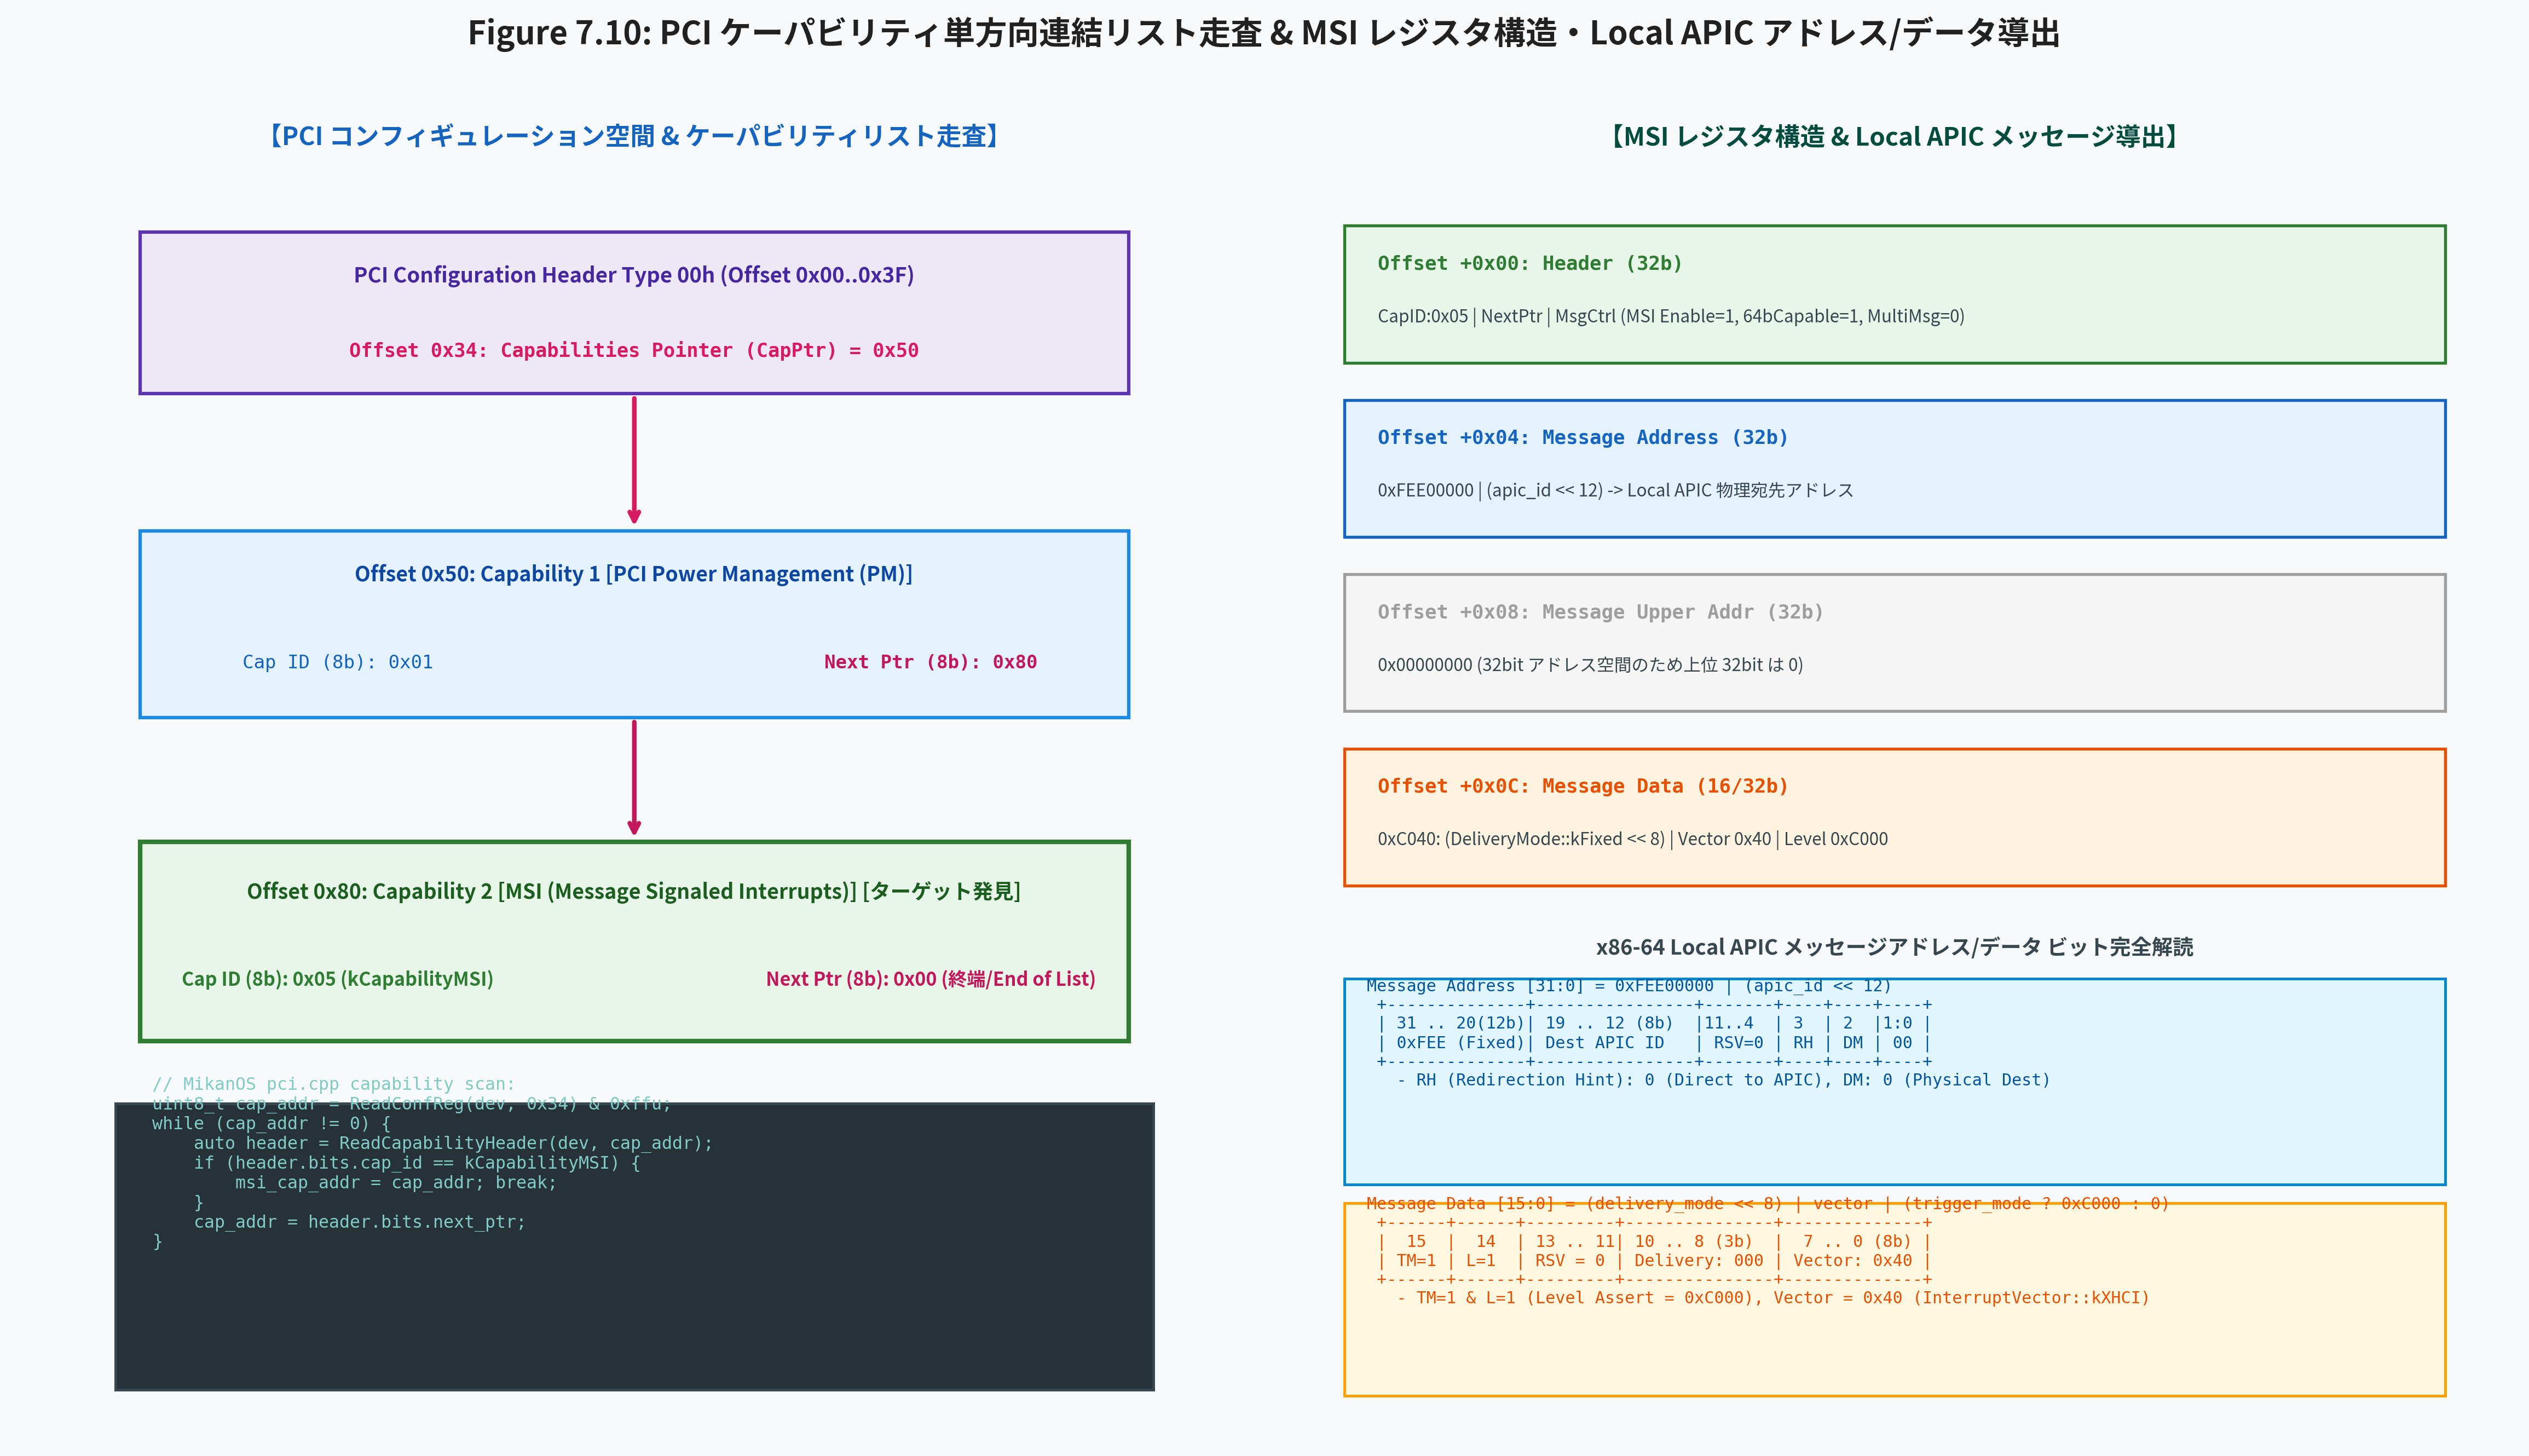

In [3]:
# Figure 7.10: PCI ケーパビリティ単方向連結リスト走査 & MSI レジスタ構造・Local APIC アドレス/データ導出
fig7_10_path = "result/fig7_10_pci_capability_linked_list_and_msi_register.png"
common.plot_pci_capability_linked_list_and_msi_register(fig7_10_path)
display(Image(filename=fig7_10_path, width=950))


## 5. MikanOS における MSI 設定コードの完全解読

### 5.1 `ConfigureMSIFixedDestination` の実装
`kernel/pci.cpp` における MSI 設定の最上位 API である `ConfigureMSIFixedDestination` は、先ほど導出した計算式そのものをコード化したものです：

```cpp
// kernel/pci.cpp
Error ConfigureMSIFixedDestination(
    const Device& dev, uint8_t apic_id,
    MSITriggerMode trigger_mode, MSIDeliveryMode delivery_mode,
    uint8_t vector, unsigned int num_vector_exponent) {
  uint32_t msg_addr = 0xfee00000u | (apic_id << 12);
  uint32_t msg_data = (static_cast<uint32_t>(delivery_mode) << 8) | vector;
  if (trigger_mode == MSITriggerMode::kLevel) {
    msg_data |= 0xc000;
  }
  return ConfigureMSI(dev, msg_addr, msg_data, num_vector_exponent);
}
```

---

### 5.2 カーネル起動フロー（`KernelMain`）における連携
`kernel/main.cpp` では、xHCI コントローラの初期化と割り込み有効化が以下の美しいシーケンスで接続されています：

```cpp
// 1. IDT への登録とロード (7.4節)
const uint16_t cs = GetCS();
SetIDTEntry(idt[InterruptVector::kXHCI], MakeIDTAttr(DescriptorType::kInterruptGate, 0),
            reinterpret_cast<uint64_t>(IntHandlerXHCI), cs);
LoadIDT(sizeof(idt) - 1, reinterpret_cast<uintptr_t>(&idt[0]));

// 2. BSP の Local APIC ID を取得し、xHCI の MSI を設定 (本節 7.5)
const uint8_t bsp_local_apic_id =
  *reinterpret_cast<const uint32_t*>(0xfee00020) >> 24;
pci::ConfigureMSIFixedDestination(
    *xhc_dev, bsp_local_apic_id,
    pci::MSITriggerMode::kLevel, pci::MSIDeliveryMode::kFixed,
    InterruptVector::kXHCI, 0);

// 3. xHCI コントローラの稼働開始
xhc.Run();

// 4. CPU の割り込みフラグ (IF) を有効化!
__asm__("sti");

// 5. アイドルループ: CPU を HLT 状態で待機させ、割り込み契機でウェイクアップ
while (1) __asm__("hlt");
```

> [!TIP]
> **ポーリングループから HLT 待機への転換**:
> 第6章では `while(1) { ProcessEvent(xhc); }` で CPU が 100% 回り続けていましたが、本節によって **「マウスが動いた瞬間だけ xHCI が MSI を発火し、CPU が `IntHandlerXHCI` を実行して画面を更新し、再び HLT で省電力スリープに戻る」** という理想的なイベント駆動アーキテクチャが完成しました！


In [4]:
# C++20 スタンドアロン検証プログラム (src/ch07/msi_interrupt_sim.cpp) のコンパイルと実行
import subprocess

cpp_source = "../src/ch07/msi_interrupt_sim.cpp" if os.path.exists("../src/ch07/msi_interrupt_sim.cpp") else "src/ch07/msi_interrupt_sim.cpp"
bin_output = "/tmp/ch07_msi_interrupt_sim"

compile_cmd = ["g++", "-std=c++20", "-O2", "-Wall", "-Wextra", cpp_source, "-o", bin_output]
print("🔨 Compiling C++20 Standalone Verification Binary...")
subprocess.run(compile_cmd, check=True)

print("🚀 Running Verification Suite:")
result = subprocess.run([bin_output], capture_output=True, text=True, check=True)
print(result.stdout)


🔨 Compiling C++20 Standalone Verification Binary...


🚀 Running Verification Suite:
  MikanOS Section 7.5: PCI MSI Configuration Verification
[Test 1] PCI CapabilityHeader Bitfield Layout & Union Integrity...
  -> CapabilityHeader size = 4 bytes, raw data = 0x00816005 [OK]
[Test 2] MSICapability Bitfield Structure & Control Bits...
  -> MSI Enable=1, MultiMsgCapable=2^3, 64bCapable=1 [OK]
[Test 3] Local APIC Message Address Calculation...
  -> BSP Addr: 0xfee00000, Core 1 Addr: 0xfee01000 [OK]
[Test 4] Local APIC Message Data Formulation (Vector & Trigger)...
  -> Edge Data: 0x40, Level Data: 0xc040 [OK]
[Test 5] PCI Capability Linked List Traversal...
  -> Found MSI at 0x70: Enabled=1, MsgAddr=0xfee00000, MsgData=0xc040 [OK]
[Test 6] Error Handling for Device without MSI (kNoPCIMSI)...
  -> Correctly returned error: kNoPCIMSI [OK]
[Test 7] 32-bit vs 64-bit MSI Capability Register Offset...
  -> 32-bit (MsgData at +8) and 64-bit (MsgData at +12) offsets verified [OK]
  ALL 7 TESTS PASSED SUCCESSFULLY!



In [5]:
# Python PCIDeviceMSISimulator による対話型実験
from common import (
    PCIDeviceMSISimulator,
    MSITriggerMode,
    MSIDeliveryMode,
    format_msi_address,
    format_msi_data,
)

# 1. 仮想 xHCI デバイスの作成 (Bus 0, Dev 20, Func 0)
sim_xhc = PCIDeviceMSISimulator(bus=0, device=20, function=0)

# 2. ケーパビリティリストの構築
# 0x34 -> 0x50 (Power Management) -> 0x80 (MSI) -> 0x00 (End)
sim_xhc.write_conf_reg(0x34, 0x50)
sim_xhc.add_capability(cap_addr=0x50, cap_id=0x01, next_ptr=0x80)
sim_xhc.setup_msi_capability(cap_addr=0x80, next_ptr=0x00, addr_64_capable=True)

print("=== 実験 1: BSP (Core 0) への MSI 設定 ===")
ok, msg = sim_xhc.configure_msi_fixed_destination(
    apic_id=0,
    trigger_mode=MSITriggerMode.kLevel,
    delivery_mode=MSIDeliveryMode.kFixed,
    vector=0x40,
)
print("設定成否:", ok, "| 詳細:", msg)
msi_state = sim_xhc.read_msi_capability(0x80)
print(f"MSI Enable: {msi_state.msi_enable}")
print(f"Message Address: 0x{msi_state.msg_addr:08X} (Local APIC Base: 0xFEE00000, APIC ID: 0)")
print(f"Message Data:    0x{msi_state.msg_data:04X} (Vector: 0x40, Level Assert: 0xC000)")

print("\n=== 実験 2: マルチコア AP Core 3 へのルーティング ===")
addr_core3 = format_msi_address(apic_id=3)
data_core3 = format_msi_data(vector=0x45, delivery_mode=MSIDeliveryMode.kFixed, trigger_mode=MSITriggerMode.kEdge)
print(f"Core 3 宛先アドレス: 0x{addr_core3:08X} (bit 13:12 に APIC ID 3 が反映)")
print(f"Core 3 エッジトリガーデータ: 0x{data_core3:04X} (Vector 0x45, Trigger=Edge)")


=== 実験 1: BSP (Core 0) への MSI 設定 ===
設定成否: True | 詳細: Configured MSI at 0x80
MSI Enable: True
Message Address: 0xFEE00000 (Local APIC Base: 0xFEE00000, APIC ID: 0)
Message Data:    0xC040 (Vector: 0x40, Level Assert: 0xC000)

=== 実験 2: マルチコア AP Core 3 へのルーティング ===
Core 3 宛先アドレス: 0xFEE03000 (bit 13:12 に APIC ID 3 が反映)
Core 3 エッジトリガーデータ: 0x0045 (Vector 0x45, Trigger=Edge)


## 6. 理解度確認チェック & 演習問題

以下の問題で、本節で学んだ MSI のハードウェア制御とビット演算の理解を確認してください。

---

### 【問題 1】(ビット導出)
ある PCI デバイスに対して、Local APIC ID が `4` である CPU コア宛てに、割り込みベクタ番号 `0x52`、固定配送モード (`kFixed`)、レベルトリガー (`kLevel`) で MSI を設定したい。
このとき設定すべき **Message Address (32bit)** および **Message Data (16bit)** の 16 進数表記として正しいものを求めよ。

<details>
<summary>▶ 解答・解説（クリックで展開）</summary>

- **Message Address**:
  $$\text{Address} = \mathtt{0xFEE0\_0000} \mid (4 \ll 12) = \mathtt{0xFEE0\_0000} \mid \mathtt{0x0000\_4000} = \mathbf{\mathtt{0xFEE0\_4000}}$$
- **Message Data**:
  固定配送モードは `0`、ベクタは `0x52`、レベルトリガー時は $\mathtt{0xC000}$（bit 15 と bit 14）をセットするため：
  $$\text{Data} = (0 \ll 8) \mid \mathtt{0x52} \mid \mathtt{0xC000} = \mathbf{\mathtt{0xC052}}$$
</details>

---

### 【問題 2】(ケーパビリティ走査)
PCI コンフィギュレーション空間のオフセット `0x34` を読み取ったところ、値が `0x40` であった。
オフセット `0x40` の 32 ビット DWORD を読み取ると `0x0080_7001` であった。
このデバイスの最初のケーパビリティの ID、および次のケーパビリティの格納オフセットを答えよ。

<details>
<summary>▶ 解答・解説（クリックで展開）</summary>

- リトルエンディアンで格納された DWORD `0x0080_7001` のビット配置：
  - Byte 0 (bits 7..0): `0x01` $\rightarrow$ **Capability ID = `0x01` (PCI Power Management)**
  - Byte 1 (bits 15..8): `0x70` $\rightarrow$ **Next Capability Pointer = `0x70`**
  - Bytes 3..2 (bits 31..16): `0x0080` (Control/Status)
- したがって、最初のケーパビリティは **PM (0x01)** であり、次はオフセット **`0x70`** に存在する。
</details>

---

### 【問題 3】(アーキテクチャ考察)
従来のピン割り込み（INTx）と比較して、MSI を用いることで OS の割り込み処理遅延（レイテンシ）が劇的に削減される理由を、ハードウェアバスアクセスの観点から 2 点説明せよ。

<details>
<summary>▶ 解答・解説（クリックで展開）</summary>

1. **ピン共有に伴うポーリングアクセスの撲滅**: レガシー INTx では複数デバイスが同一ピンを共有するため、OS は共有デバイスすべてのステータスレジスタを PCI 読み出し（低速なバス往復ラウンドトリップ）して発生源を特定しなければならなかったが、MSI ではベクタ番号が直接 CPU に届くため、この探索処理が一切不要になる。
2. **メモリ書き込みトランザクションの非同期パイプライン化**: PCIe においてメモリ書き込み（Memory Write）は応答を待たずに次々と発行できる Posted Transaction であるため、バス上の待機遅延なしに即座に Local APIC へパケットが到達する。
</details>


## 7. まとめ & 次節への布石

### 📌 本節の重要ポイント総括
1. **MSI (Message Signaled Interrupts)** は、物理ピンの代わりに PCIe のメモリ書き込みパケットを用いることで、ピン共有の制約を解消し、ポーリングなしでデバイス・イベント固有のベクタを CPU へ通知する現代の標準割り込み機構である。
2. **PCI ケーパビリティリスト** はオフセット `0x34` から始まる単方向連結リストであり、各ノードの `cap_id`（MSI は `0x05`）を検査しながら `next_ptr` を辿ることで動的に拡張機能を探索できる。
3. **Local APIC メッセージアドレス** は `0xFEE00000 | (apic_id << 12)` で表され、宛先コアを指定できる。
4. **Local APIC メッセージデータ** は `(delivery_mode << 8) | vector | (trigger_mode ? 0xC000 : 0)` で構成され、レベルトリガー時には bit 15 と bit 14 がセットされて `0xC000` となる。
5. xHCI の MSI 設定が完了したことで、CPU は `hlt` 命令で省電力スリープしながら、マウスイベント発生時のみ割り込みで即座に目覚めて処理する理想的なイベント駆動 OS を実現した。

---

### 🗺️ 次節 7.6 へのロードマップ
本節により、IDT の構築（7.4）と MSI の設定（7.5）という割り込みの 2 大インフラが完成しました。
次節 **7.6「割り込みのまとめ」(`7/7.6_Interrupt_Flow_Summary.ipynb`)** では、マウスを動かした瞬間にハードウェア内部で何が起きるのか——**「USB パケット受信 $ightarrow$ xHCI Event Ring $ightarrow$ MSI パケット発行 $ightarrow$ Local APIC 受信 $ightarrow$ CPU IDT 参照 $ightarrow$ スタック自動退避 $ightarrow$ `IntHandlerXHCI` 起動 $ightarrow$ `IRETQ` 復帰」** という全ライフサイクルを 1 本の完全なフローとして統合・総括します！
